# 6. 1D Grating with Two Interleaved Inclusions: Unit-Cell Symmetry Breaking

## Physical Motivation & Learning Objectives
By placing two different dielectric inclusions within a single 1D unit cell, we break spatial inversion symmetry, allowing coupling to asymmetric modes. In this tutorial:
1. We define unit cells with multiple inclusions (`diameter1`, `diameter2`, `inclusion_a`, `inclusion_b`).
2. We compute the TE spectrum of the resulting grating.


**Legacy example.** This notebook reproduces `simo_031-1D_grating-2_inclusions.py` from the original EMUstack. The `LEGACY_PARAMS` switch in the next cell selects the inputs:

- `LEGACY_PARAMS = True` *(default)*: the legacy inputs, unchanged. T, R and A then agree with legacy EMUstack to 1e-9 (checked in `benchmarks/parity/`, `examples/` version)
- `LEGACY_PARAMS = False`: 41 wavelengths instead of 2.

In [ ]:
# True: the inputs of the original EMUstack example, unchanged.
# False: same structure, 41 wavelengths instead of 2.
LEGACY_PARAMS = True

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



## Grating Setup: Two Interleaved Inclusions

$\Lambda = 300$ nm, height 2900 nm. Inclusion a is 45 nm wide ($n = 5.0$), inclusion b is 81 nm wide ($n = 3.0$), in a background of $n = 1.46$, with air above and below.

In [2]:
wavelengths = np.linspace(400, 800, 2 if LEGACY_PARAMS else 41)
period = 300.0  # nm

light_list = [objects.Light(wl, max_order_PWs=5, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)

grating = objects.NanoStruct(
    '1D_array', period,
    diameter1=int(round(0.15 * period)),
    diameter2=int(round(0.27 * period)),
    height_nm=2900.0,
    background=materials.Material(1.46),
    inclusion_a=materials.Material(5.0),
    inclusion_b=materials.Material(3.0),
    loss=True, lc_bkg=0.0051, plt_msh=False
)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_grt = grating.calc_modes(light)
    stk = Stack((sim_sub, sim_grt, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

with concurrent.futures.ThreadPoolExecutor(max_workers=24) as executor:
    stacks_list = list(executor.map(simulate_stack, light_list))


## Transmission and Reflection Spectra


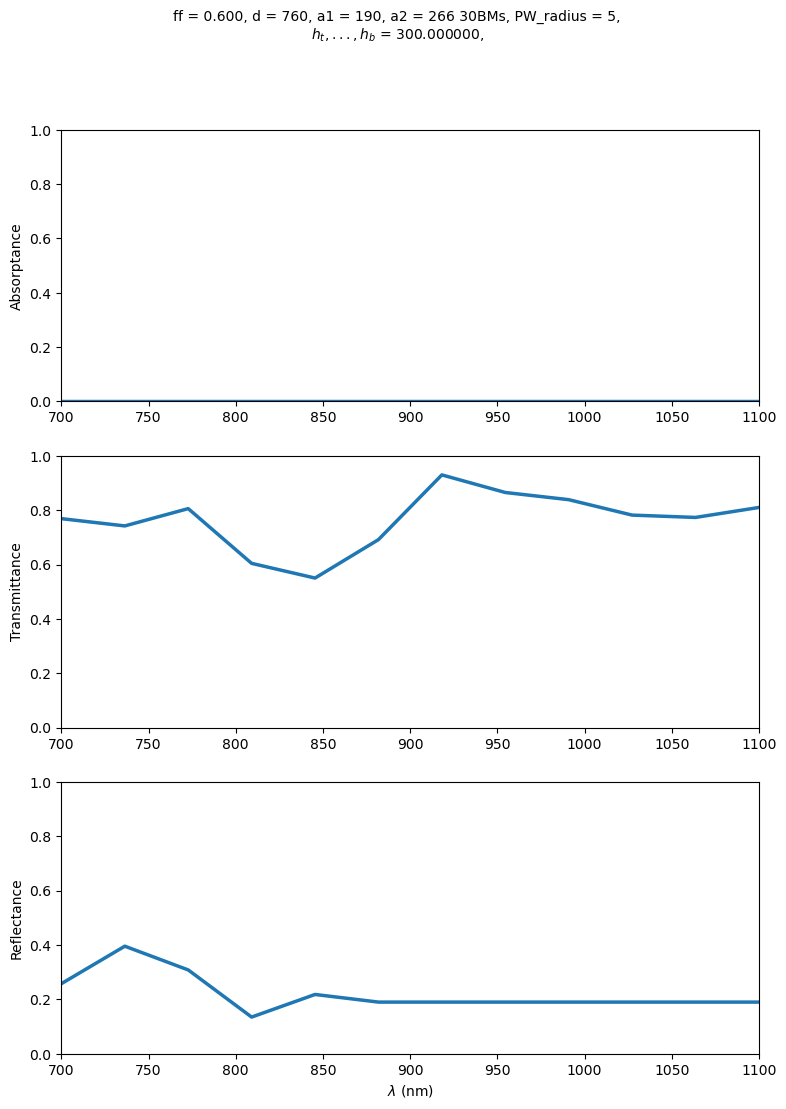

In [3]:
fig_tra = plotting.t_r_a_plots(stacks_list, save_pdf=False, save_txt=False)
plt.show()


## Physical Interpretation
- The structure is lossless, so $T + R = 1$.
- As in the single-inclusion grating, many Bloch modes interfere inside the 2.9 µm-thick layer and $T$ swings between almost 0 and almost 1 faster than the sampling can follow.
- Only the zeroth diffraction order propagates outside the grating between 400 and 800 nm ($\lambda > \Lambda$).
